All configuration and model checks passed.
[0.    0.025 0.05  0.075 0.1  ]
(60, 3, 2)
(60, 3)


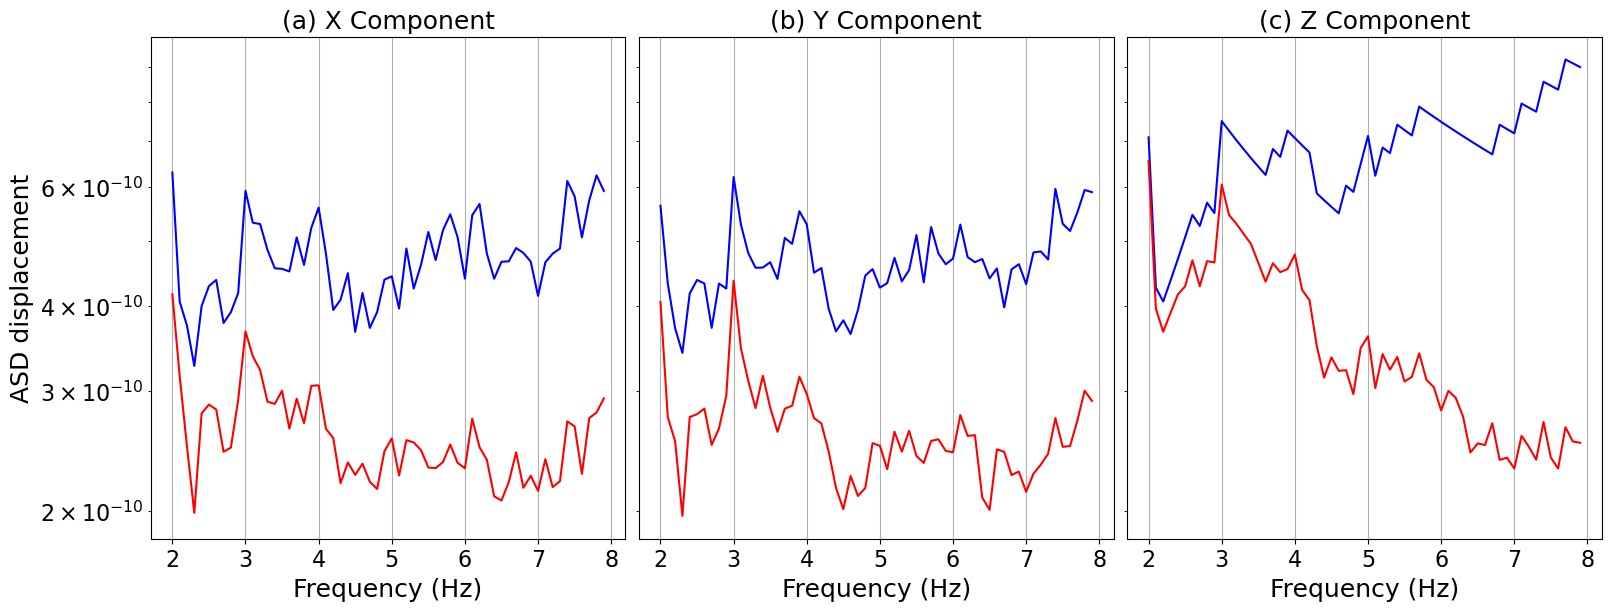

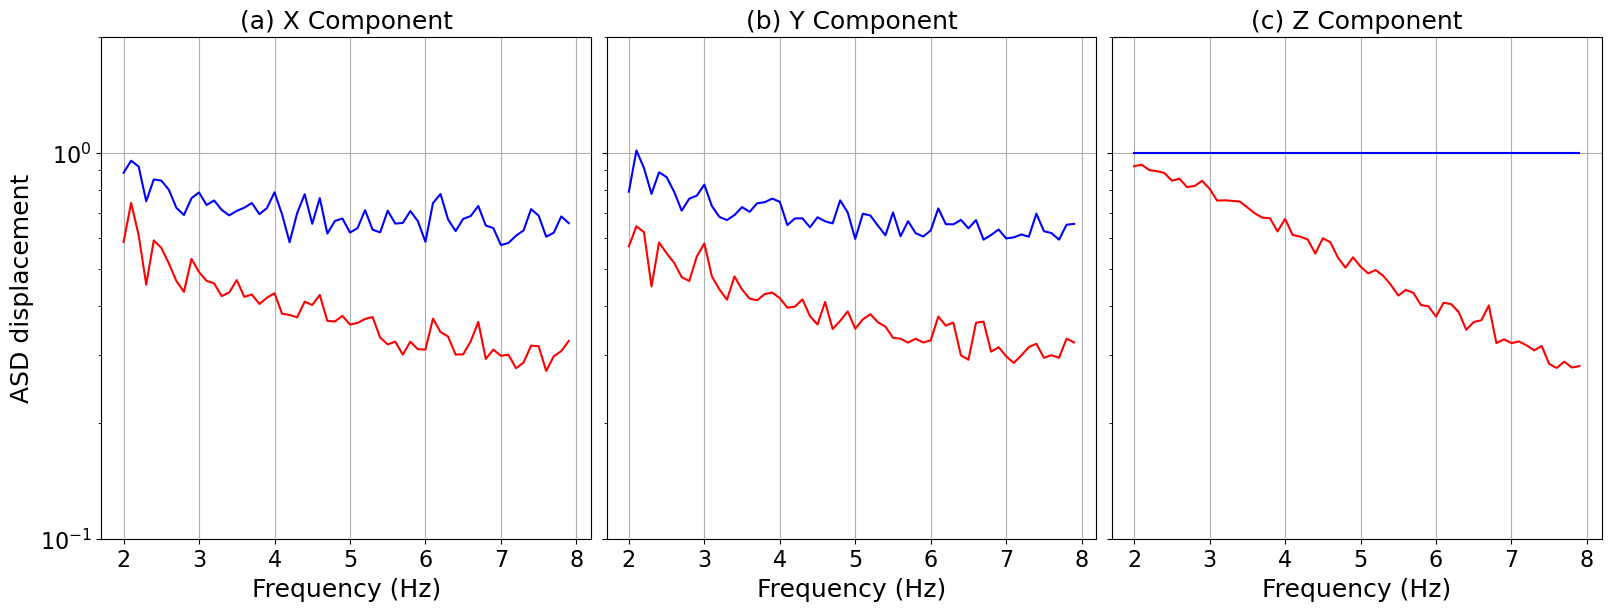

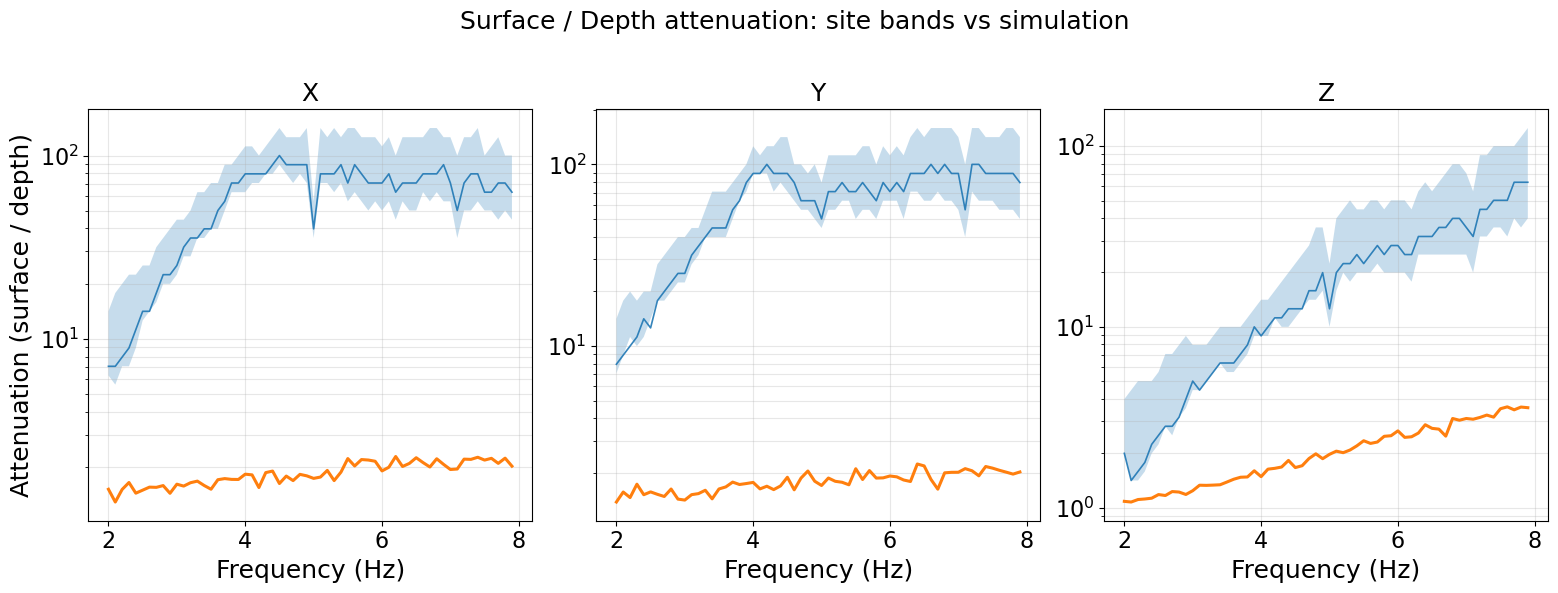

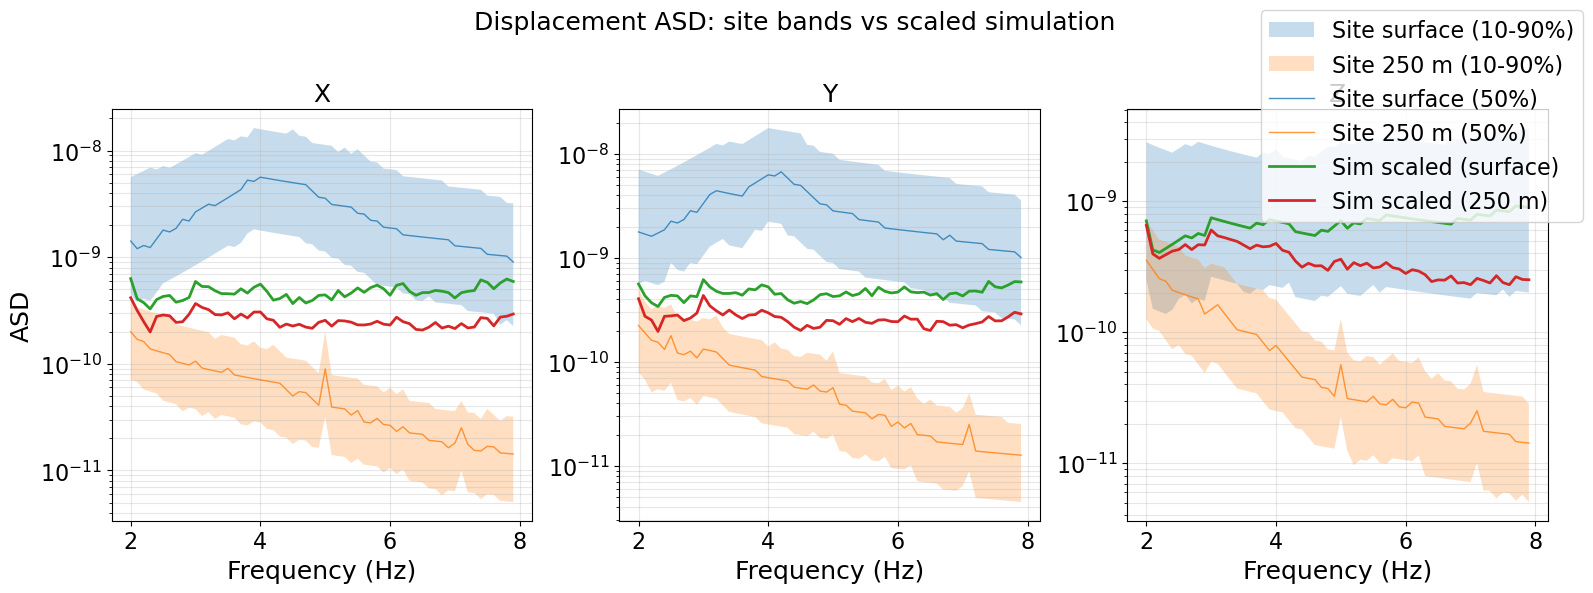

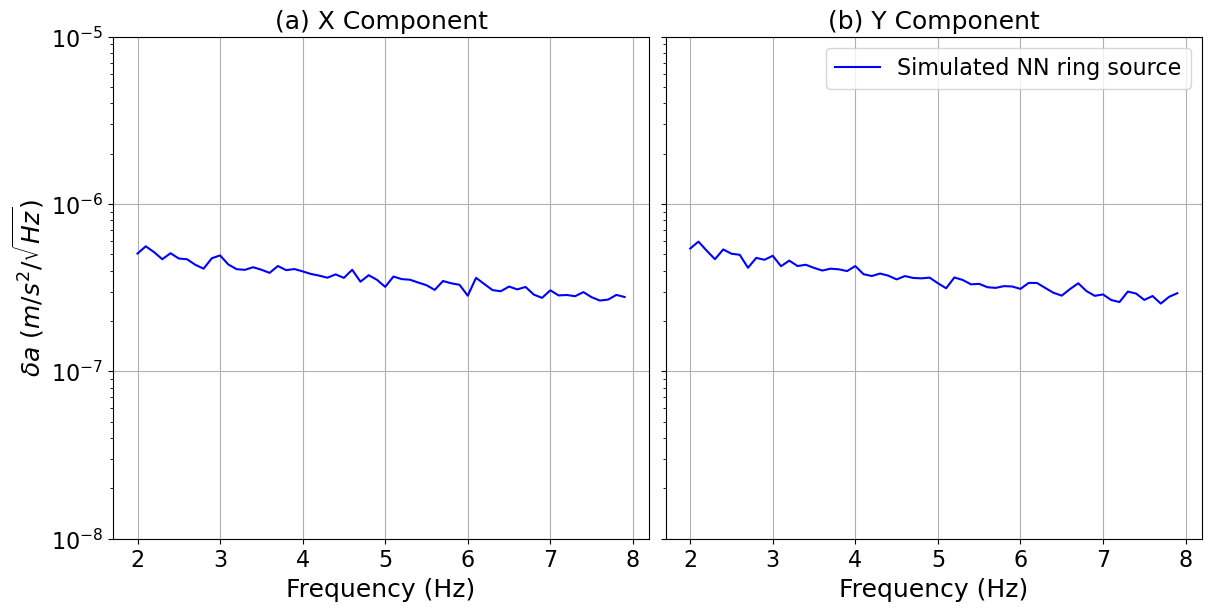

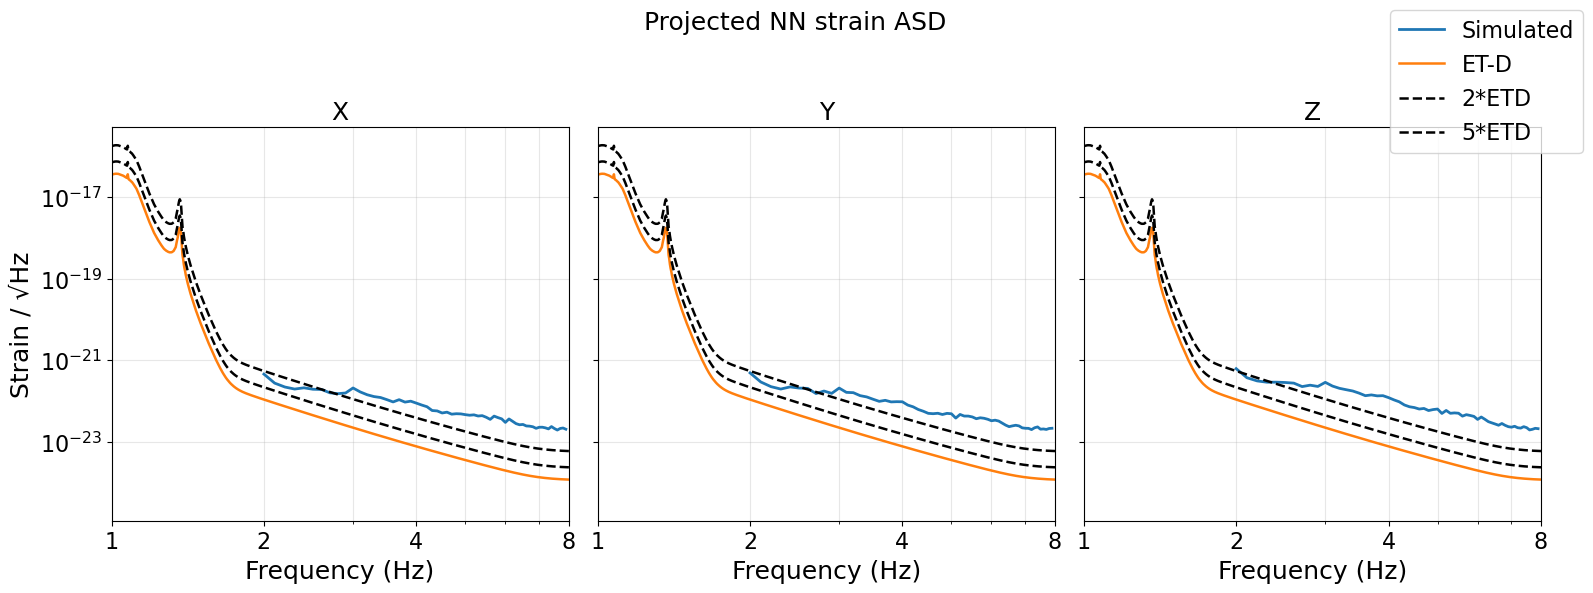

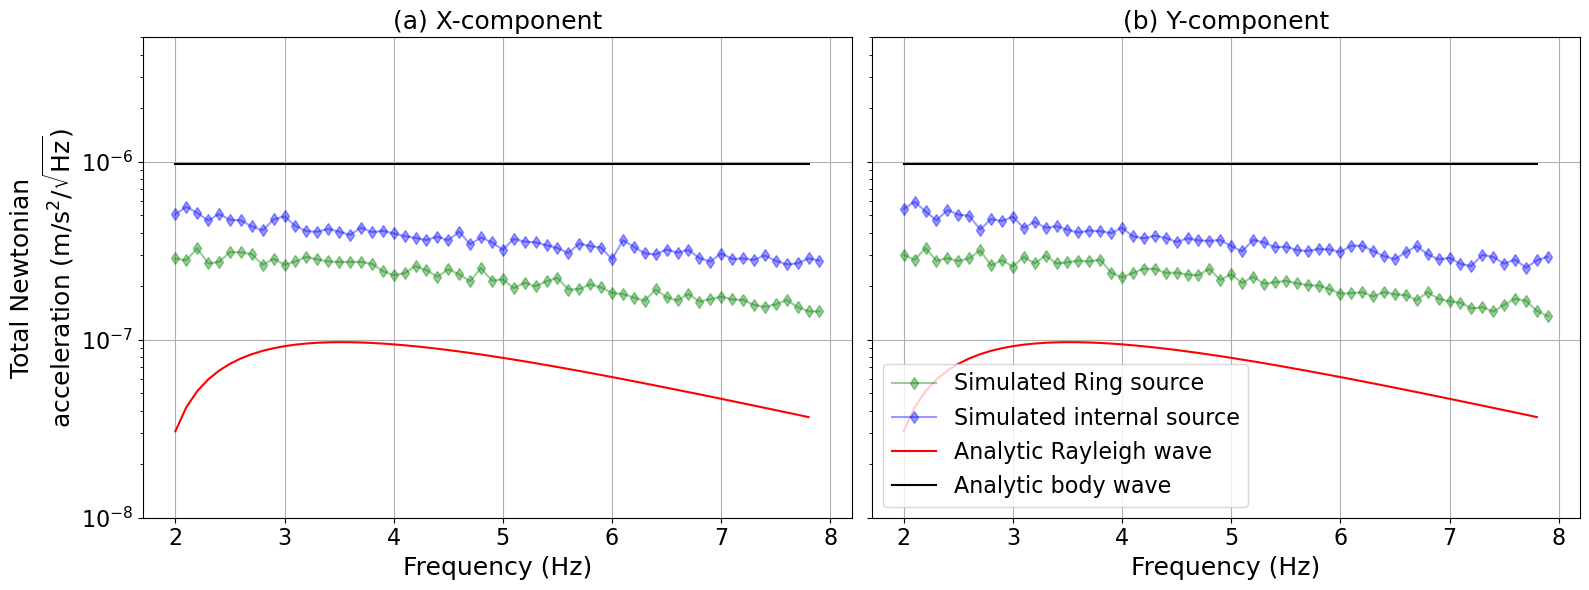

In [ ]:
# this script plots the Newtonian acceleration estimated at the test-mass from a stochastic
# seismic displacement field produced from vertical and horizontal forces acting on the surface
# this version supports reading the NN per realization both from the older version of the simulation
# and the new one which supports multiple test-masses being saved in the simulated NN
# plots are generated directly for the publocation, in which ifFirstTime is used a flag
# Because we intend to compare the NN from a ring source geometry and internal source geometry,
# the first run is for the ring source, and the second run is for the internal source, and a joint plot is generated

import numpy as np
import os
import matplotlib.pyplot as plt
import pickle
from scipy.io import loadmat
from modules import configLoader
from modules import validateInputs
from modules import simDisp
from modules import NNCompute
from modules import plotUtils
from modules import NNPP

def main():

    plotUtils.set_plot_style(style='large')
    simVersion = 'new' # swicth to 'new' if you are using current distribution after Oct, 2026
    firstTime = False
    # this can be switched to either ring or internal source geometry
    # the first run is always toi assemble the ring case, and then run again the internal case
    # with the ring case saved, and then a joint plot is generated
    configFile="/home/koley/CavityResults/SphFullRunConfig/configParseFullFieldHomoInternal.ini"
    # path for the final comparitive plot,
    figPathPdf = "/home/koley/CavityResults/AllTutOut/SphFullFieldHomoRing/Figures/FullFieldHomoJoint.pdf"
    
    fileSavePath = "/home/koley/CavityResults/AllTutOut/SphFullFieldHomoInternal/Figures/fullFieldHomoInternal.npz"
    if not firstTime:
        fileSavePathOld = "/home/koley/CavityResults/AllTutOut/SphFullFieldHomoRing/Figures/fullFieldHomoRing.npz"

    config = configLoader.load_config(configFile)

    # the cavity stays the same for both internal and ring source geometry, so we can load it here
    allCavities = configLoader.loadCavities('/home/koley/CavityResults/SphFullRunConfig/SingleSphCavity.ini')
    validateInputs.validateInputs(config)

    fMin = config.fMin; fMax = config.fMax; df = config.df;# units in Hz
    tMax = config.tMax; nSamp = config.nSamp
    outDispRea = config.outDispPathRea # like "/data/gravwav/koley/OutDispRea/"
    nRea = config.nRea # number of realizations
    freqOut, _, _ = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)

    # new part added
    cavDepthAll = np.zeros((len(allCavities),))
    for cavNo, cav in enumerate(allCavities):    
        if(cav["shape"]=="cuboid"):
            cavDepthAll[cavNo] = cav["zC"]
        elif(cav["shape"] == 'sphere'):
            cavDepthAll[cavNo] = cav["zC"]
        else:
            ValueError('Unsupported cavity type')
    
    cavDepthUse = min(cavDepthAll)

    itmAC = config.itmAC; itmAB = config.itmAB; etmCA = config.etmCA; etmBA = config.etmBA
    itmAll = np.vstack((itmAC,))
    nTM = len(itmAll[:,0])

    # two depth points for scaling, displacement saved per realization
    zList = [0.0,cavDepthUse]

     # assembles the rms displacement field at the surface and near the cavity over all realizations
    dispPointAllRea, attnAllRea, freqDisp = simDisp.assembleSurfDeepDispAllRea(outDispRea, zList, freqOut, nRea)

    # check the shape, should be nFreqx3x2 (2 denotes the two depths - surface and 250 m or so)
    print(np.shape(dispPointAllRea))

    # scales the rms of the simulated displacement field to match either the surface or depth
    # ASD as measured on the field
    # It always finds the scale factor to match a desired component, the other components
    # should match naturallly if the geology and source distrubution are accurate
    # never try to scale every component independently, that is wrong!
    scaledSimDisp, asdSurfX, asdSurfY, asdSurfZ, asdBHX, asdBHY, asdBHZ = NNPP.scaleDisp(
        dispPointAllRea, freqOut, config, scaleComp='Z', scaleDepth = 'surface', scaleToTrue=True)

    # scales the desired component ASD either at depth or surface to 1
    # this scaling is important when using analytical formulations
    scaledSimDispFalse, asdSurfXF, asdSurfYF, asdSurfZF, asdBHXF, asdBHYF, asdBHZF = NNPP.scaleDisp(
        dispPointAllRea, freqOut, config, scaleComp='Z', scaleDepth = 'surface', scaleToTrue=False)
    
    # make plot
    figDisp, axDisp = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDisp[:,:,0], '0 m deep', 'b', fig=None, axs=None, 
                                         quantity="ASD displacement")
    figDisp, axDisp = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDisp[:,:,1], '250 m deep', 'r', fig=figDisp, axs=axDisp, 
                                         quantity="ASD displacement")
    
    figDispF, axDispF = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDispFalse[:,:,0], '0 m deep', 'b', fig=None, axs=None, 
                                         quantity="ASD displacement")
    figDispF, axDispF = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDispFalse[:,:,1], '250 m deep', 'r', fig=figDispF, axs=axDispF, 
                                         quantity="ASD displacement")
    
    axDispF[0].set_ylim(0.1,2);axDispF[1].set_ylim(0.1,2);axDispF[2].set_ylim(0.1,2)
    
    attnSim, attnX, attnY, attnZ = NNPP.getAttn(dispPointAllRea,freqOut,config)

    figAttn, axAttn = plotUtils.plotAttn(freqOut, attnSim, attnX, attnY, attnZ)
    
    figSh, axSh = plotUtils.plotScaledVsSiteASD(freqOut, scaledSimDisp, asdSurfX, asdSurfY, asdSurfZ,
                                                asdBHX, asdBHY, asdBHZ)
    
    #nnTotAllRea, fNN = NNCompute.assembleNNAllRea(outDispRea,freqOut, nRea)
    if(simVersion=='old'):
            nnTotAllRea, nnVolAllRea, nnSurfAllRea, fNN = NNCompute.assembleNNAllRea(outDispRea,freqOut, nRea)
    else:
        nnTotAllReaAllTM, nnVolAllReaAllTM, nnSurfAllReaAllTM, fNN = NNCompute.assembleNNAllReaAllTM(outDispRea,freqOut, nRea, nTM)
        nnTotAllRea = nnTotAllReaAllTM[:,:,0]
    # the third dimension should be gone now, and the rest is compatible again
    print(np.shape(nnTotAllRea))

    # scale the Newtonian acceleration at the test-mass such that ASD of the simulated diplacemnet field
    # either on the surface or at depth for a chosen component is 1.0, note it is 1.0 because
    # scaleToTrue is turned to False
    # this is particularly useful for comparing with analytical expresssions that scale with
    # observed ASDs either on the surface (Rayleigh NN) or depth (bodyNN)
    scaledNN, *__ = NNPP.scaleNN(
        nnTotAllRea, dispPointAllRea, freqOut, config, scaleComp="Z", scaleDepth="surface",
        scaleToTrue=False)

    # get the NN analytical curves for Rayleigh waves
    NNRay,freqNNRay = NNCompute.getAnalyticRayNN(config,250)
    NNBody, minNN, freqNNBody = NNCompute.getAnalyticBodyNN(config,p=1/3)

    figNN, axNN = plotUtils.plotPSDDeepSurfMulti(fNN, scaledNN[:,0:2], 'Simulated NN ring source', 'b', fig=None, axs=None, 
                                         quantity=r"$\delta a \ (m/s^2/\sqrt{Hz})$",subFigs=2)
   
    # save the scaledNN
    np.savez(fileSavePath,fNN=freqOut,scaledNN=scaledNN)

    #axNN[0].legend()
    axNN[1].legend(loc="upper right")
    #axNN[2].legend()
    axNN[0].set_ylim(10**-8,10**-5)
    axNN[1].set_ylim(10**-8,10**-5)
    #axNN[2].set_ylim(10**-8,10**-5)

    # same as the previous NN scaling, but now instead of 1.0 the desired component of the simulated
    # displacement field either on the surface or at depth is scaled to the one observed
    # at the site, this is useful for getting the true site-based NN estimate, and projecting to
    # Einstein Telescope design sensitivity
    scaledNNToTrue, *__ = NNPP.scaleNN(
        nnTotAllRea, dispPointAllRea, freqOut, config, scaleComp="Z", scaleDepth="surface",
        scaleToTrue=True)

    # project the Newtonian acceleration at a single test-mass to ET design strain
    # assuming uncorrelated contributions from the four test-massses of a ITF
    nnProj, ETD = NNPP.NNProjectToET(scaledNNToTrue, fNN, config)

    figSens, axSens = plotUtils.plotNNStrainET(fNN, nnProj, ETD, title="Projected NN strain ASD", xlim=(1, 8), xscale="log",
                   yscale="log", comp_labels=("X", "Y", "Z"), sim_label="Simulated", etd_label="ET-D",
                   legend_once=True, fig=None,axs=None)
    
    
    plotUtils.set_plot_style(style='large')
    # create a figure to save
    figOut, axOut = plt.subplots(1,2,figsize=(16,6),sharey=True)
    if(firstTime):
        axOut[0].plot(freqOut,scaledNN[:,0],'bd-',alpha=0.4,label='Simulated')
        axOut[0].plot(freqNNRay,NNRay,'r',label='Analytic')
        axOut[0].set_ylabel(r'Total Newtonian' + "\n" +  r'acceleration $\mathrm{(m/s}^2/\sqrt{\mathrm{Hz}})$')
        axOut[0].set_xlabel('Frequency (Hz)')
        axOut[0].grid()
        axOut[0].set_title('(a) X-component')
        axOut[0].set_yscale('log')

        axOut[1].plot(freqOut,scaledNN[:,1],'bd-',alpha=0.4,label='Simulated')
        axOut[1].plot(freqNNRay,NNRay,'r',label='Analytic')
        axOut[1].set_xlabel('Frequency (Hz)')
        axOut[1].legend()
        axOut[1].grid()
        axOut[1].set_title('(b) Y-component')
        axOut[1].set_ylim(10**-8,5*10**-6)
        axOut[1].set_yscale('log')
        
        plt.tight_layout()

    else:
        # do a joint plot
        dataPrevious = np.load(fileSavePathOld) # the ring case is loaded now

        # load the previous case which may be ring or internal
        axOut[0].plot(dataPrevious['fNN'],dataPrevious['scaledNN'][:,0],'gd-',alpha=0.4,label='Simulated Ring source')
        axOut[0].plot(freqOut,scaledNN[:,0],'bd-',alpha=0.4,label='Simulated internal source')
        axOut[0].plot(freqNNRay,NNRay,'r',label='Analytic Rayleigh wave')
        axOut[0].plot(freqNNBody,NNBody,'k',label='Analytic body wave')
        axOut[0].set_ylabel(r'Total Newtonian' + "\n" +  r'acceleration $\mathrm{(m/s}^2/\sqrt{\mathrm{Hz}})$')
        axOut[0].set_xlabel('Frequency (Hz)')
        axOut[0].grid()
        axOut[0].set_title('(a) X-component')
        axOut[0].set_yscale('log')

        axOut[1].plot(dataPrevious['fNN'],dataPrevious['scaledNN'][:,1],'gd-',alpha=0.4,label='Simulated Ring source')
        axOut[1].plot(freqOut,scaledNN[:,1],'bd-',alpha=0.4,label='Simulated internal source')
        axOut[1].plot(freqNNRay,NNRay,'r',label='Analytic Rayleigh wave')
        axOut[1].plot(freqNNBody,NNBody,'k',label='Analytic body wave')
        axOut[1].set_xlabel('Frequency (Hz)')
        axOut[1].legend()
        axOut[1].grid()
        axOut[1].set_title('(b) Y-component')
        axOut[1].set_ylim(10**-8,5*10**-6)
        axOut[1].set_yscale('log')
                
        plt.tight_layout()

    # activate it only during the second run
    if not firstTime:       
        figOut.savefig(figPathPdf, bbox_inches="tight",transparent=False,metadata={"Creator": "Python/Matplotlib"})
    

if __name__ == "__main__":
    main()